In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
import random

# --- Helper Functions ---


def create_sequences_from_groups(data_groups, target_column, scaler, seq_length):
    """Creates sequences for all groups in a grouped DataFrame."""
    all_X, all_y = [], []
    for _, group_df in data_groups:
        if len(group_df) > seq_length:
            scaled_group = scaler.transform(
                group_df[target_column].values.reshape(-1, 1)
            )
            for i in range(len(scaled_group) - seq_length):
                x = scaled_group[i : i + seq_length]
                y = scaled_group[i + seq_length]
                all_X.append(x)
                all_y.append(y)
    return np.array(all_X), np.array(all_y)


def build_lstm_model(seq_length):
    """Builds a simple, standard LSTM model for validation."""
    model = Sequential(
        [LSTM(50, activation="relu", input_shape=(seq_length, 1)), Dense(1)]
    )
    model.compile(optimizer="adam", loss="mse")
    return model


def calculate_mape(y_true, y_pred):
    """Calculates Mean Absolute Percentage Error, safely handling zeros."""
    mask = y_true != 0
    y_true_safe, y_pred_safe = y_true[mask], y_pred[mask]
    if len(y_true_safe) == 0:
        return np.nan
    mape = np.mean(np.abs((y_true_safe - y_pred_safe) / y_true_safe)) * 100
    print(
        f"   (Note: MAPE calculated on {len(y_true_safe)} of {len(y_true)} non-zero data points)"
    )
    return mape


# --- Main Validation Function ---


def run_full_validation(real_path, synthetic_path, target_col, group_col, seq_length):
    """Runs a complete validation suite comparing a real dataset to a synthetic one."""
    print("--- 🚀 Starting Full Validation Suite ---")

    # Load Data
    try:
        real_df = pd.read_csv(real_path)
        synthetic_df = pd.read_csv(synthetic_path)
        print(f"✅ Data loaded successfully.\n")
    except FileNotFoundError as e:
        print(f"❌ Error loading files: {e}")
        return

    # --- Section 1: Descriptive Statistics ---
    print("--- 📊 Section 1: Descriptive Statistics ---")
    real_desc = real_df[target_col].describe()
    synth_desc = synthetic_df[target_col].describe()
    comparison_df = pd.DataFrame({"Real Data": real_desc, "Synthetic Data": synth_desc})
    print(comparison_df)
    print("\n")

    # --- Section 2: Visual Comparison of Random Groups ---
    print("--- 🎨 Section 2: Visual Comparison of Random Groups ---")
    real_groups = real_df.groupby(group_col)
    synthetic_groups = synthetic_df.groupby(group_col)
    common_ids = list(
        set(real_df[group_col].unique()) & set(synthetic_df[group_col].unique())
    )

    if not common_ids:
        print(
            "   No common group IDs found between real and synthetic data. Skipping plot."
        )
    else:
        sample_ids = random.sample(common_ids, min(3, len(common_ids)))
        print(f"   Plotting random sample groups: {sample_ids}")
        fig, axes = plt.subplots(
            len(sample_ids), 1, figsize=(15, 4 * len(sample_ids)), squeeze=False
        )
        for i, group_id in enumerate(sample_ids):
            ax = axes[i, 0]
            real_group = real_groups.get_group(group_id)
            synthetic_group = synthetic_groups.get_group(group_id)
            ax.plot(
                real_group[target_col].values,
                label="Real Data",
                color="blue",
                alpha=0.8,
            )
            ax.plot(
                synthetic_group[target_col].values,
                label="Synthetic Data",
                color="red",
                linestyle="--",
                alpha=0.8,
            )
            ax.set_title(f"Comparison for {group_col}: {group_id}")
            ax.legend()
            ax.grid(True, linestyle="--", alpha=0.6)
        plt.tight_layout()
        plt.show()

    # --- Section 3: Distribution Comparison ---
    print("\n--- 📈 Section 3: Distribution Comparison (KDE Plot) ---")
    plt.figure(figsize=(10, 6))
    sns.kdeplot(
        real_df[target_col], label="Real Data", color="blue", fill=True, clip=(0, None)
    )
    sns.kdeplot(
        synthetic_df[target_col],
        label="Synthetic Data",
        color="red",
        fill=True,
        clip=(0, None),
    )
    plt.title(f'Overall Distribution Comparison for "{target_col}"')
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.show()

    # --- Section 4: Autocorrelation Analysis ---
    print("\n--- ⏳ Section 4: Autocorrelation (ACF & PACF) ---")
    fig, axes = plt.subplots(2, 2, figsize=(15, 8))
    fig.suptitle("Autocorrelation Analysis on Flattened Series", fontsize=16)

    plot_acf(
        real_df[target_col].dropna(), lags=40, ax=axes[0, 0], title="ACF - Real Data"
    )
    plot_pacf(
        real_df[target_col].dropna(), lags=40, ax=axes[0, 1], title="PACF - Real Data"
    )
    plot_acf(
        synthetic_df[target_col].dropna(),
        lags=40,
        ax=axes[1, 0],
        title="ACF - Synthetic Data",
    )
    plot_pacf(
        synthetic_df[target_col].dropna(),
        lags=40,
        ax=axes[1, 1],
        title="PACF - Synthetic Data",
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    # --- Section 5: TSTR Evaluation with LSTM ---
    print("\n--- 🤖 Section 5: Train-Synthetic-Test-Real (TSTR) Evaluation ---")
    scaler = MinMaxScaler()
    scaler.fit(real_df[target_col].values.reshape(-1, 1))

    print("   Creating sequences within each group...")
    X_train, y_train = create_sequences_from_groups(
        synthetic_groups, target_col, scaler, seq_length
    )
    X_test, y_test = create_sequences_from_groups(
        real_groups, target_col, scaler, seq_length
    )

    if X_train.shape[0] < 10 or X_test.shape[0] < 10:
        print("❌ Could not create enough sequences for a reliable TSTR evaluation.")
    else:
        print(
            f"   Generated {X_train.shape[0]} training sequences from synthetic data."
        )
        print(f"   Generated {X_test.shape[0]} testing sequences from real data.")

        print("   Building and training LSTM model on synthetic data...")
        tstr_model = build_lstm_model(seq_length)
        tstr_model.fit(X_train, y_train, epochs=50, batch_size=128, verbose=0)

        print("   Evaluating model on real data sequences...")
        predictions_scaled = tstr_model.predict(X_test, verbose=0)
        predictions_actual = scaler.inverse_transform(predictions_scaled)
        y_test_actual = scaler.inverse_transform(y_test)

        print("\n   --- TSTR Performance Metrics ---")
        rmse = np.sqrt(mean_squared_error(y_test_actual, predictions_actual))
        mae = mean_absolute_error(y_test_actual, predictions_actual)
        mse = mean_squared_error(y_test_actual, predictions_actual)
        mape = calculate_mape(y_test_actual.flatten(), predictions_actual.flatten())
        r2 = 1 - (np.sum((y_test_actual - predictions_actual) ** 2) / np.sum((y_test_actual - np.mean(y_test_actual)) ** 2))

        print(f"   RMSE: {rmse:.4f}")
        print(f"   MAE:  {mae:.4f}")
        print(f"   MSE:  {mse:.4f}")
        print(f"   MAPE: {mape:.2f}%")
        print(f"   R²:   {r2:.4f}")

        print("\n--- 📈 Section 6: TSTR Prediction Visualization (Sample) ---")
        plt.figure(figsize=(15, 7))
        plot_range = min(200, len(y_test_actual))
        plt.plot(
            y_test_actual[:plot_range], label="Real Data (Ground Truth)", color="blue"
        )
        plt.plot(
            predictions_actual[:plot_range],
            label="LSTM Predictions",
            color="red",
            linestyle="--",
        )
        plt.title(f"TSTR Predictions vs. Real Data (First {plot_range} Samples)")
        plt.legend()
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.show()

    print("\n--- ✅ Validation Complete ---")

--- 🚀 Starting Full Validation Suite ---
✅ Data loaded successfully.

--- 📊 Section 1: Descriptive Statistics ---
         Real Data  Synthetic Data
count  3786.000000     3786.000000
mean    156.924194      149.660856
std     147.071416      136.266658
min       0.000000        0.000000
25%      28.000000       29.000000
50%     118.000000      122.500000
75%     257.000000      234.000000
max     751.000000      751.000000


--- 🎨 Section 2: Visual Comparison of Random Groups ---
   Plotting random sample groups: ['T1R6', 'T4R24', 'T7R25']


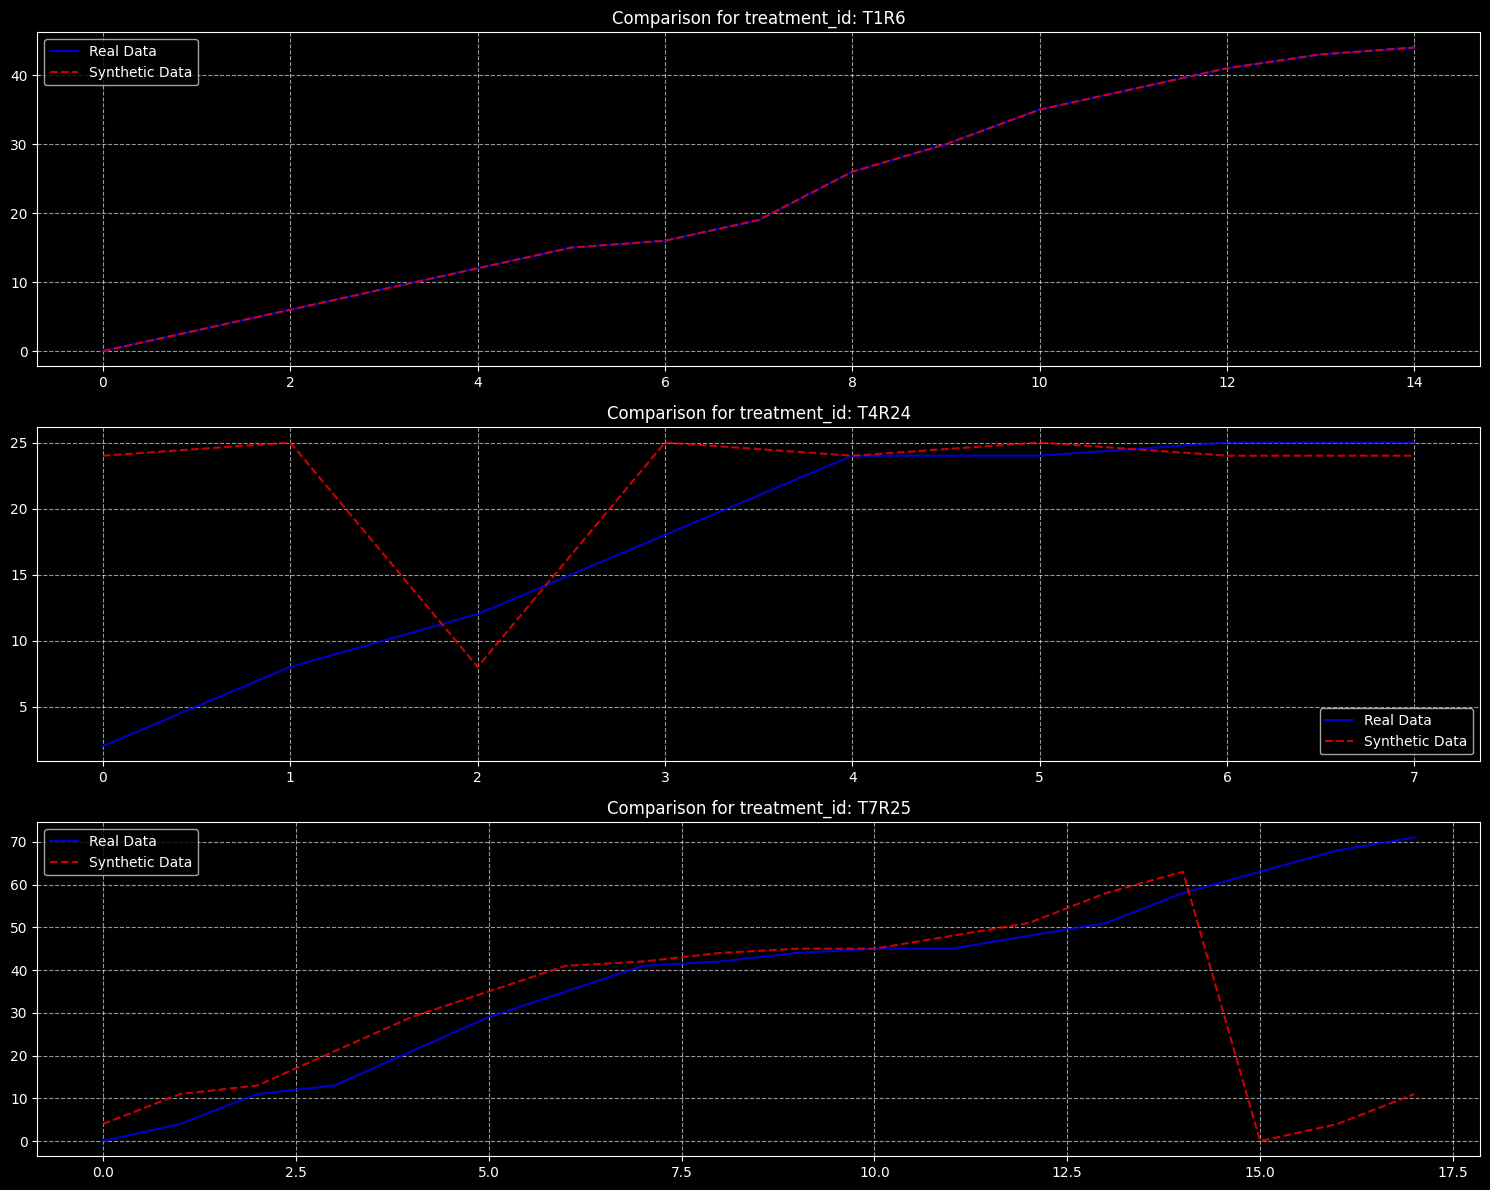


--- 📈 Section 3: Distribution Comparison (KDE Plot) ---


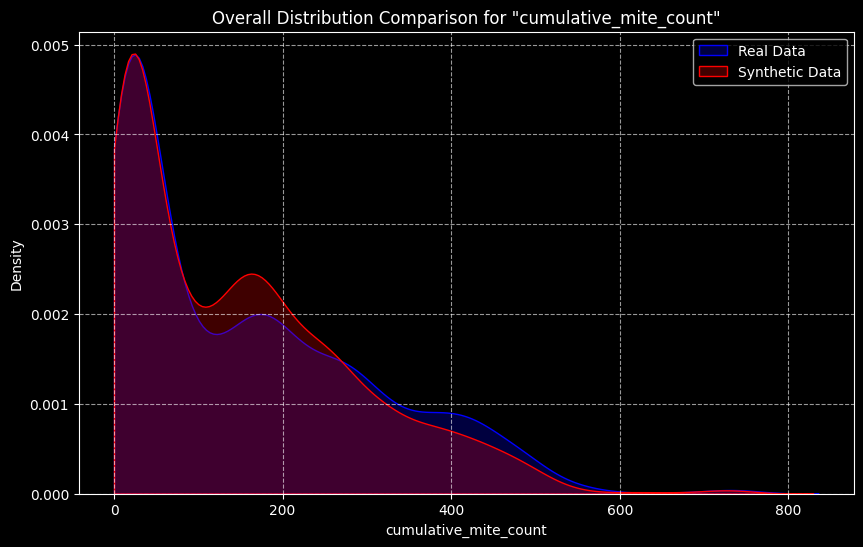


--- ⏳ Section 4: Autocorrelation (ACF & PACF) ---


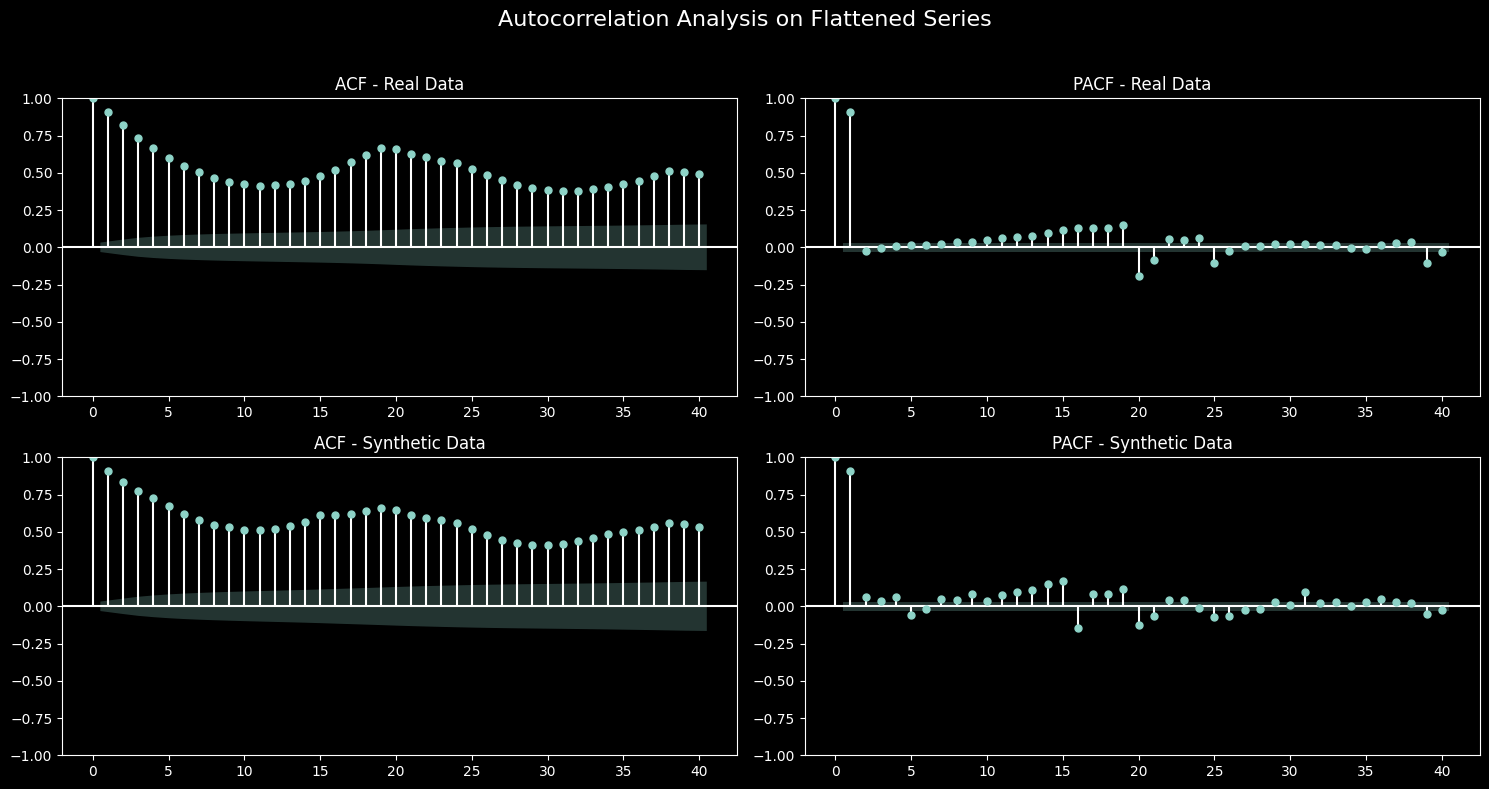


--- 🤖 Section 5: Train-Synthetic-Test-Real (TSTR) Evaluation ---
   Creating sequences within each group...
   Generated 790 training sequences from synthetic data.
   Generated 790 testing sequences from real data.
   Building and training LSTM model on synthetic data...


e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Evaluating model on real data sequences...

   --- TSTR Performance Metrics ---
   (Note: MAPE calculated on 788 of 790 non-zero data points)
   RMSE: 213.0227
   MAE:  185.3074
   MSE:  45378.6588
   MAPE: 65.78%
   R²:   -1.4239

--- 📈 Section 6: TSTR Prediction Visualization (Sample) ---


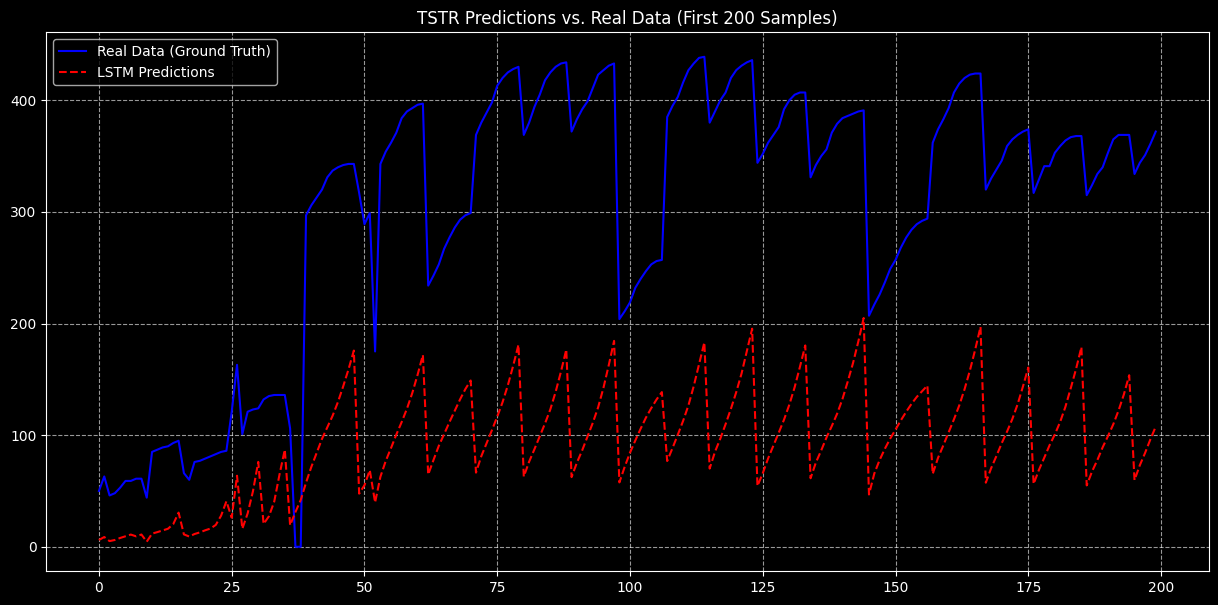


--- ✅ Validation Complete ---


In [2]:
# ===================================================================
# --- CONFIGURATION & EXECUTION ---
# ===================================================================
# 1. DEFINE YOUR FILE PATHS AND PARAMETERS HERE
REAL_DATA_PATH = "../../data/data.csv"
SYNTHETIC_DATA_PATH = (
    "../../data/syntheticData/synthetic_data_bootstrap_by_treatment_id.csv"
)
TARGET_COLUMN = "cumulative_mite_count"
GROUP_COLUMN = "treatment_id"
SEQUENCE_LENGTH = 15  # The input window size for the LSTM
# 2. RUN THE VALIDATION
run_full_validation(
    real_path=REAL_DATA_PATH,
    synthetic_path=SYNTHETIC_DATA_PATH,
    target_col=TARGET_COLUMN,
    group_col=GROUP_COLUMN,
    seq_length=SEQUENCE_LENGTH,
)

--- 🚀 Starting Full Validation Suite ---
✅ Data loaded successfully.

--- 📊 Section 1: Descriptive Statistics ---
         Real Data  Synthetic Data
count  3786.000000     3786.000000
mean    156.924194      154.983239
std     147.071416      149.605377
min       0.000000        0.000000
25%      28.000000       25.000000
50%     118.000000      106.521675
75%     257.000000      258.329272
max     751.000000      751.000000


--- 🎨 Section 2: Visual Comparison of Random Groups ---
   Plotting random sample groups: ['T5R14', 'T2R16', 'T1R10']


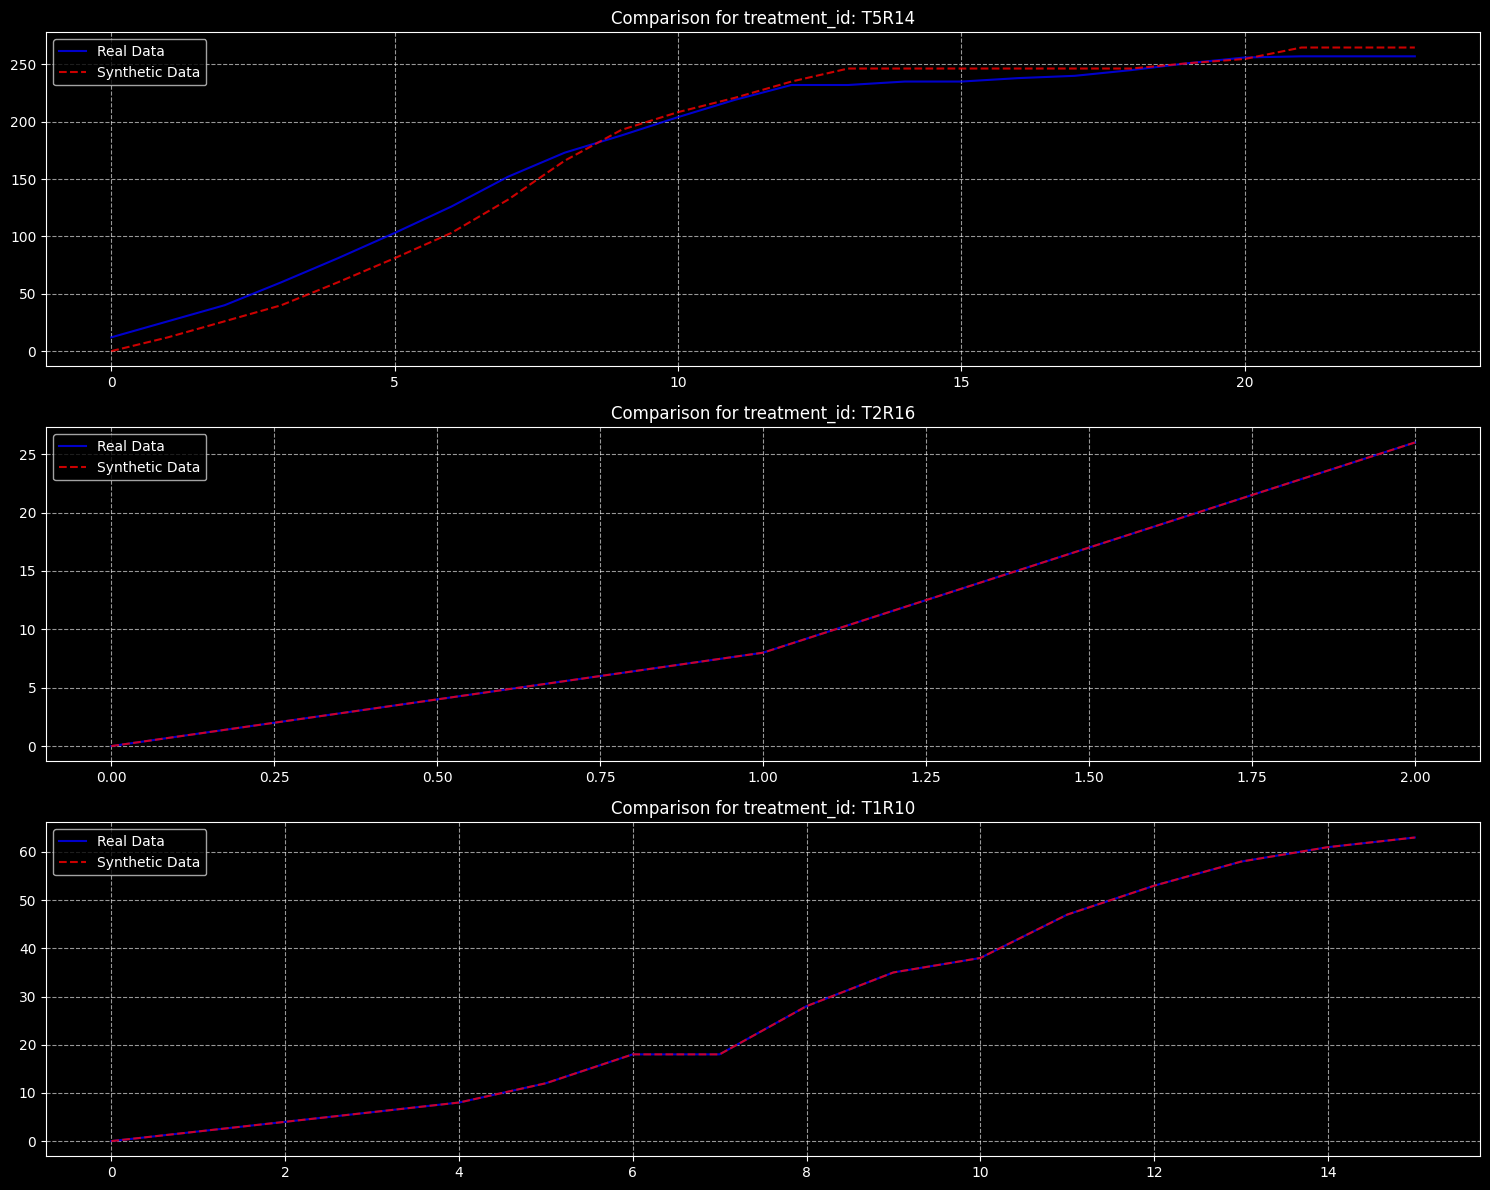


--- 📈 Section 3: Distribution Comparison (KDE Plot) ---


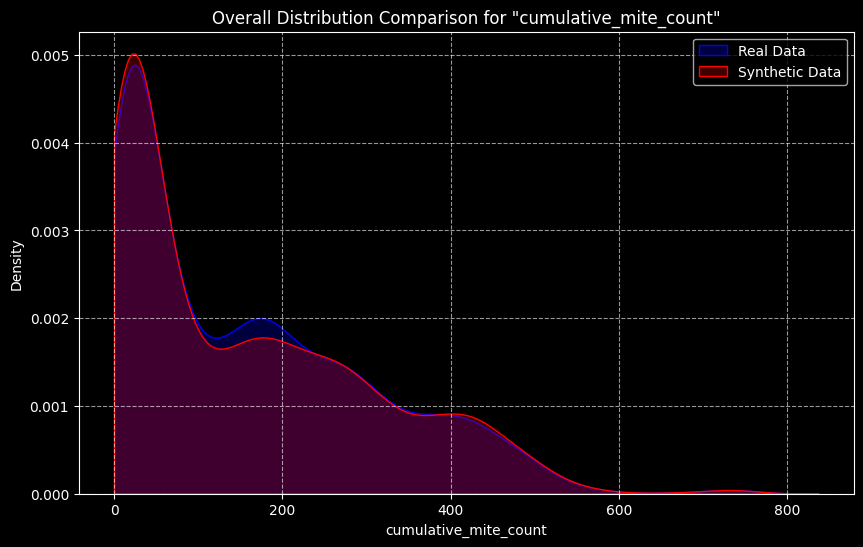


--- ⏳ Section 4: Autocorrelation (ACF & PACF) ---


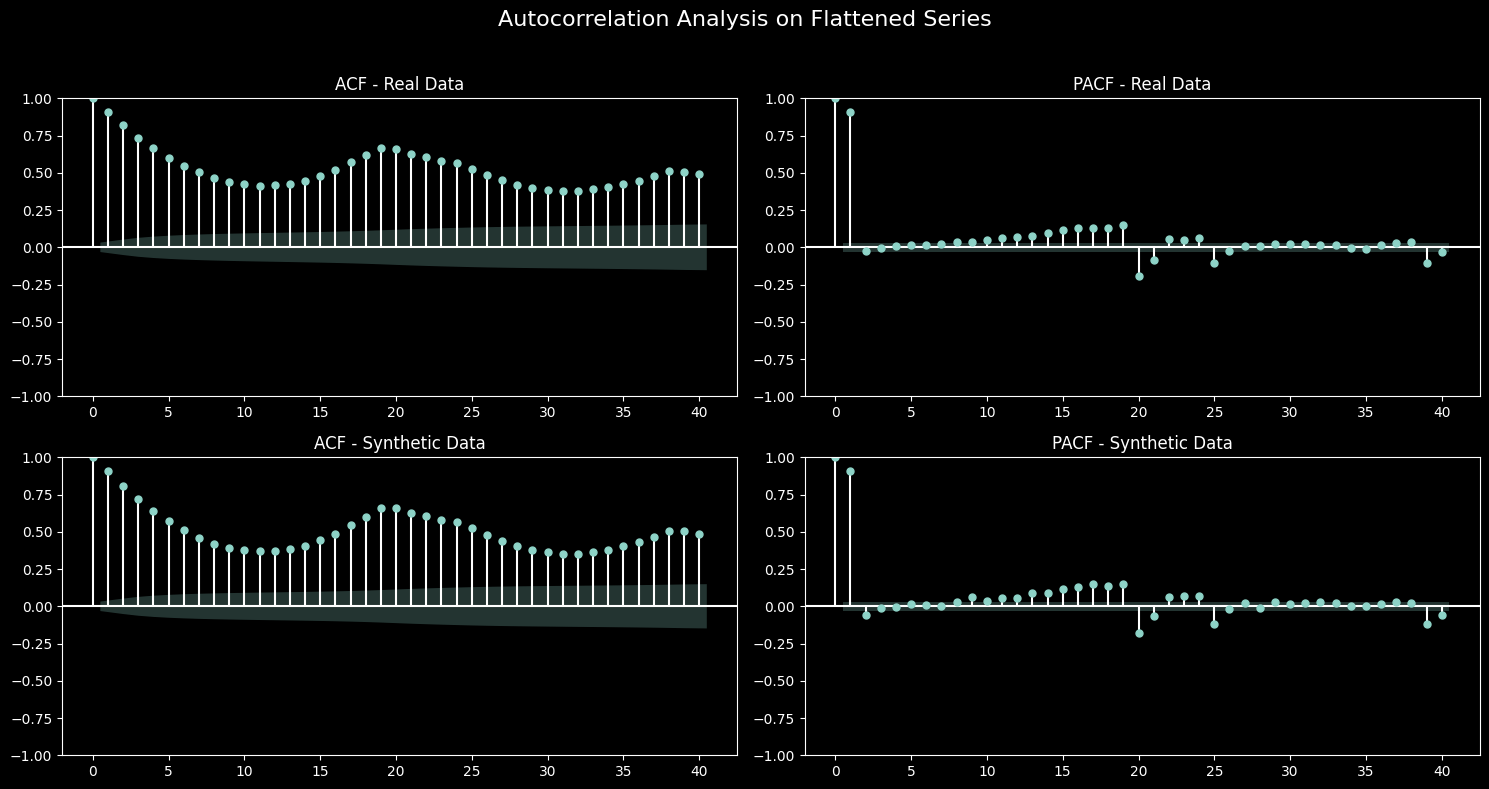


--- 🤖 Section 5: Train-Synthetic-Test-Real (TSTR) Evaluation ---
   Creating sequences within each group...
   Generated 790 training sequences from synthetic data.
   Generated 790 testing sequences from real data.
   Building and training LSTM model on synthetic data...


e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Evaluating model on real data sequences...

   --- TSTR Performance Metrics ---
   (Note: MAPE calculated on 788 of 790 non-zero data points)
   RMSE: 14.1360
   MAE:  9.5086
   MSE:  199.8267
   MAPE: 3.69%
   R²:   0.9893

--- 📈 Section 6: TSTR Prediction Visualization (Sample) ---


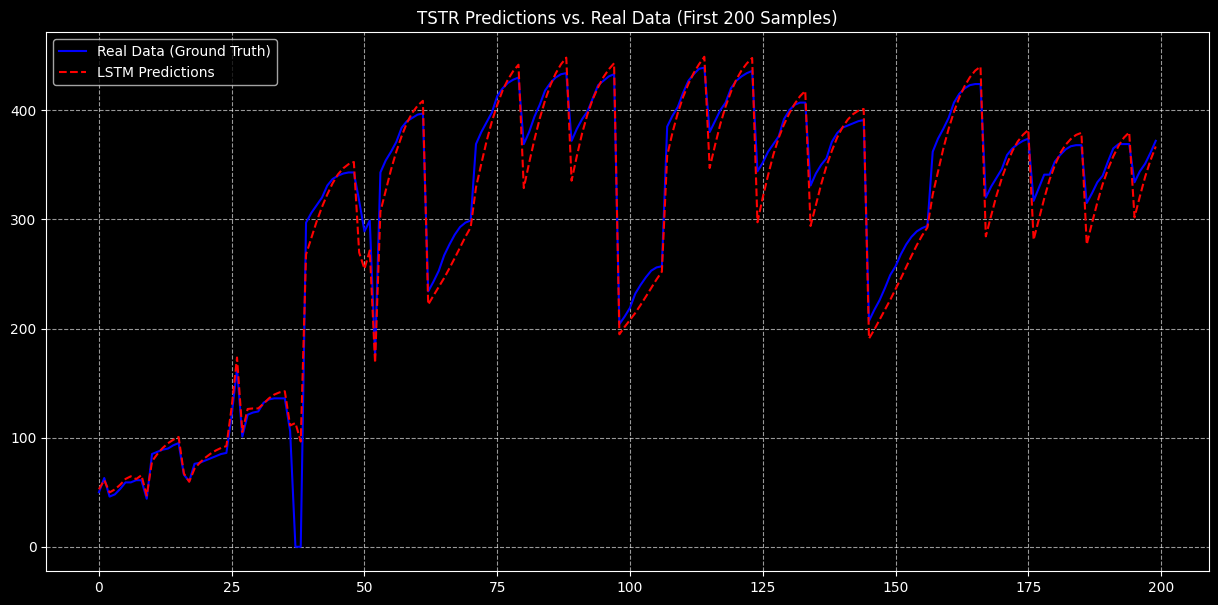


--- ✅ Validation Complete ---


In [3]:
# ===================================================================
# --- CONFIGURATION & EXECUTION ---
# ===================================================================
# 1. DEFINE YOUR FILE PATHS AND PARAMETERS HERE
REAL_DATA_PATH = "../../data/data.csv"
SYNTHETIC_DATA_PATH = "../../data/syntheticData/synthetic_data_sarima_statsmodels.csv"
TARGET_COLUMN = "cumulative_mite_count"
GROUP_COLUMN = "treatment_id"
SEQUENCE_LENGTH = 15  # The input window size for the LSTM
# 2. RUN THE VALIDATION
run_full_validation(
    real_path=REAL_DATA_PATH,
    synthetic_path=SYNTHETIC_DATA_PATH,
    target_col=TARGET_COLUMN,
    group_col=GROUP_COLUMN,
    seq_length=SEQUENCE_LENGTH,
)

--- 🚀 Starting Full Validation Suite ---
✅ Data loaded successfully.

--- 📊 Section 1: Descriptive Statistics ---
         Real Data  Synthetic Data
count  3786.000000     3786.000000
mean    156.924194      144.405972
std     147.071416      130.276039
min       0.000000        0.000000
25%      28.000000       32.901824
50%     118.000000      100.638935
75%     257.000000      235.705083
max     751.000000      561.221700


--- 🎨 Section 2: Visual Comparison of Random Groups ---
   Plotting random sample groups: ['T8R22', 'T1R20', 'T5R16']


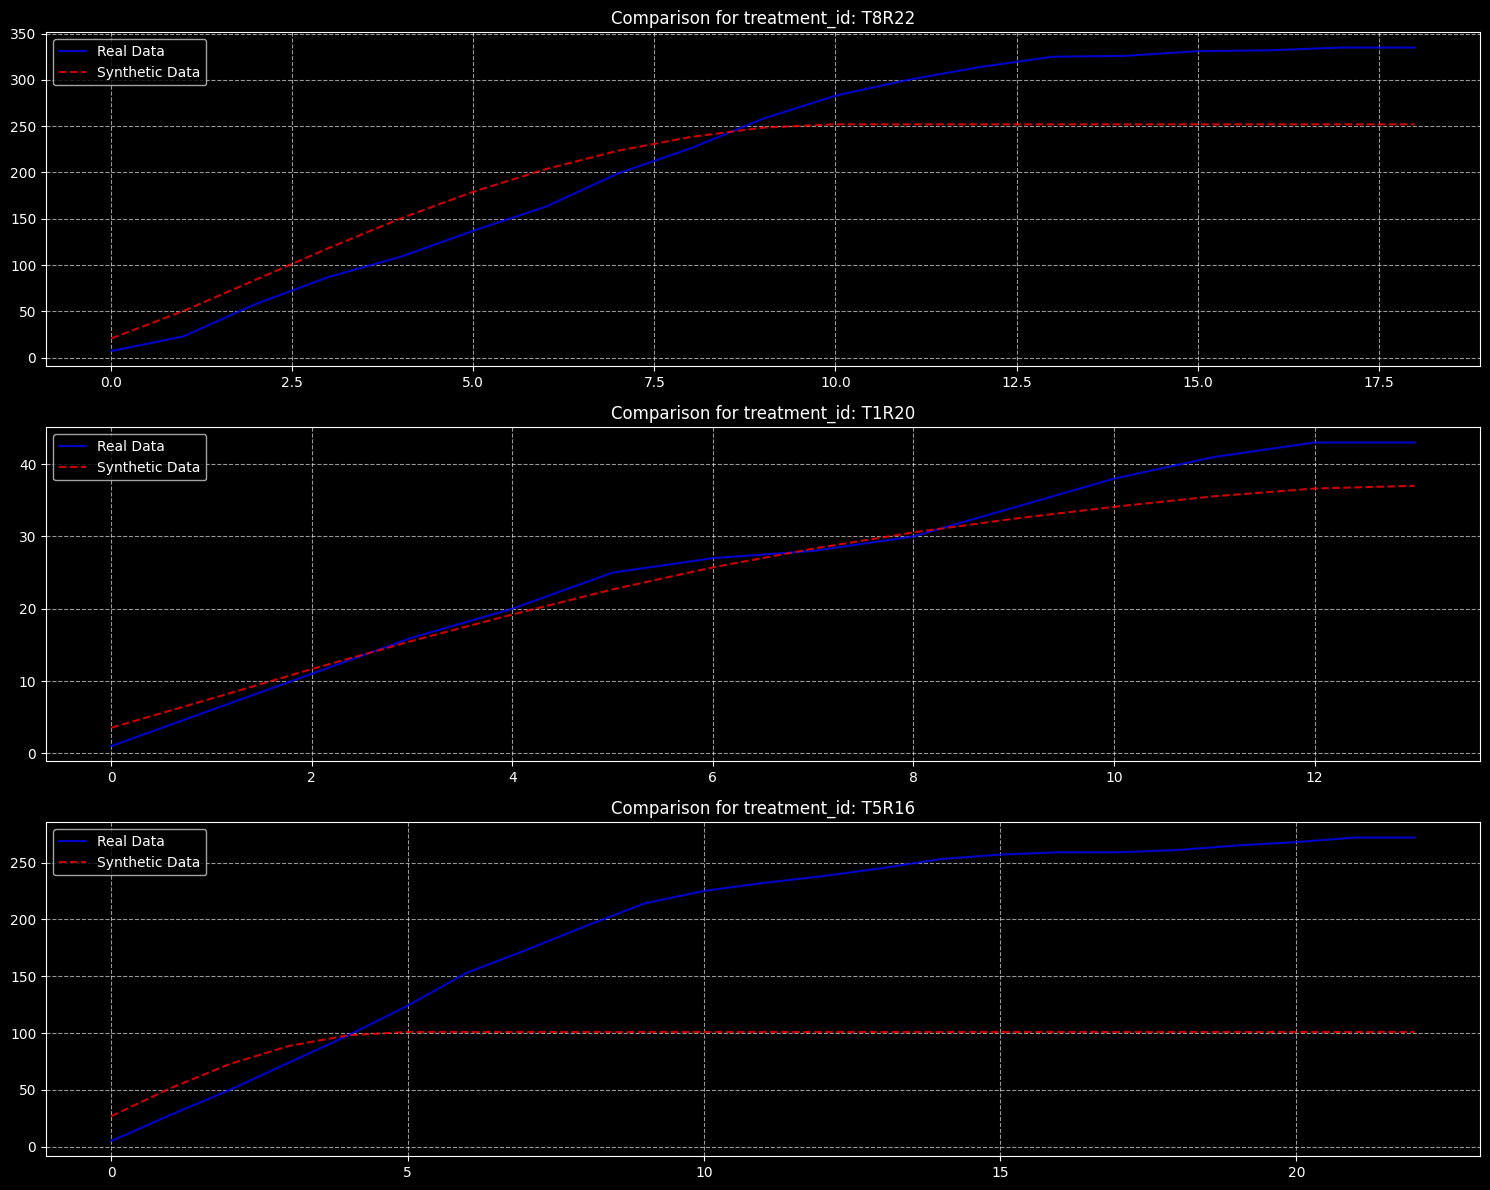


--- 📈 Section 3: Distribution Comparison (KDE Plot) ---


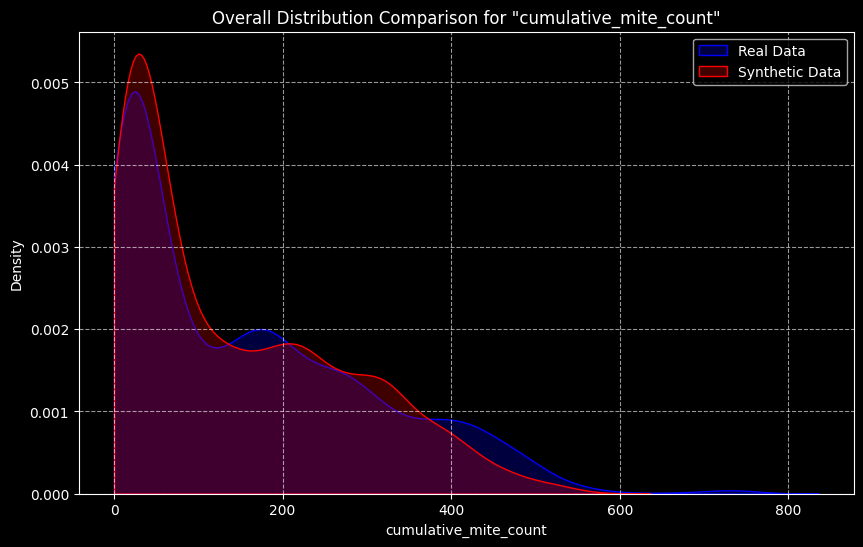


--- ⏳ Section 4: Autocorrelation (ACF & PACF) ---


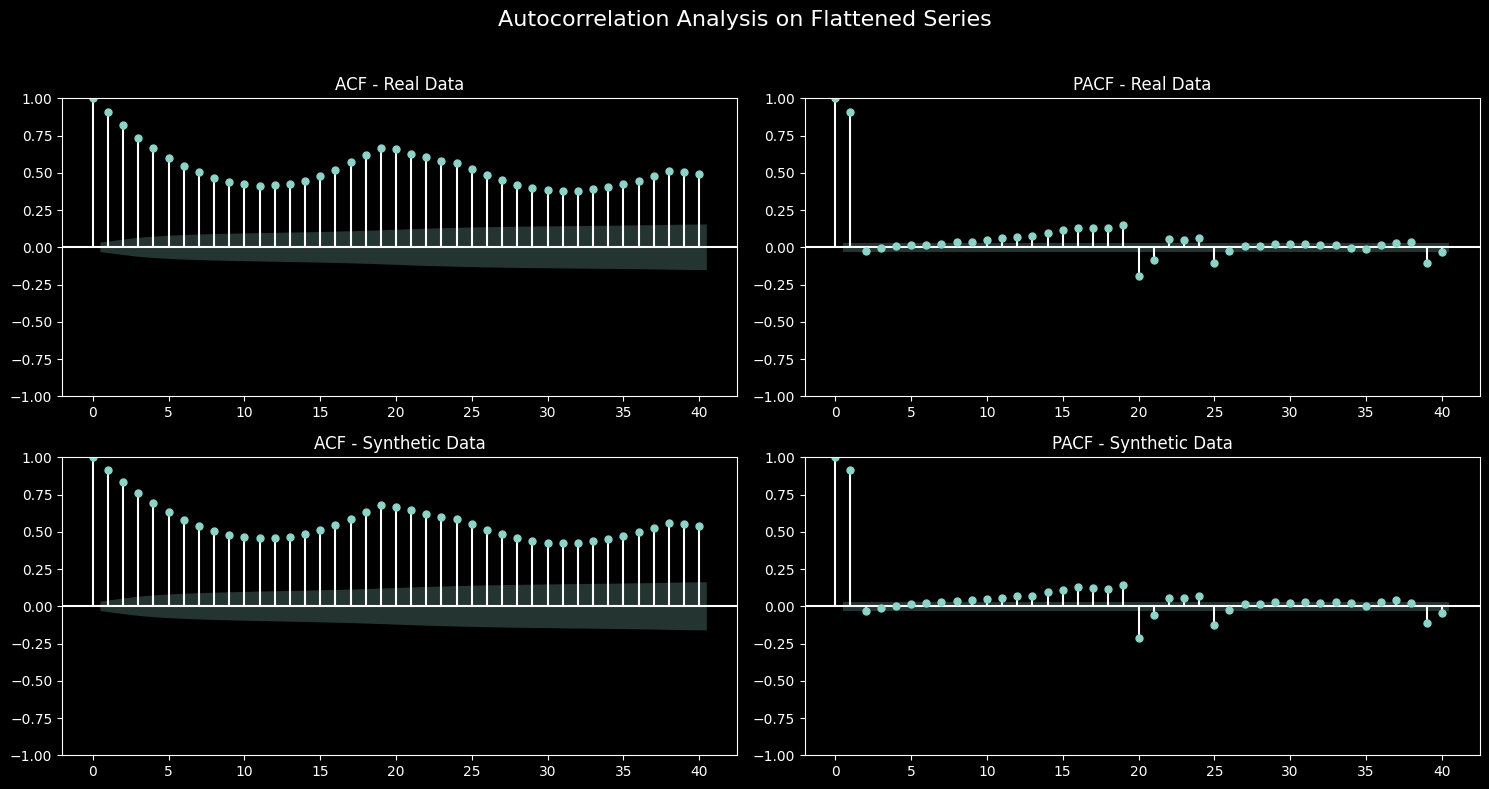


--- 🤖 Section 5: Train-Synthetic-Test-Real (TSTR) Evaluation ---
   Creating sequences within each group...
   Generated 790 training sequences from synthetic data.
   Generated 790 testing sequences from real data.
   Building and training LSTM model on synthetic data...


e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Evaluating model on real data sequences...

   --- TSTR Performance Metrics ---
   (Note: MAPE calculated on 788 of 790 non-zero data points)
   RMSE: 19.9895
   MAE:  10.9040
   MSE:  399.5813
   MAPE: 4.20%
   R²:   0.9787

--- 📈 Section 6: TSTR Prediction Visualization (Sample) ---


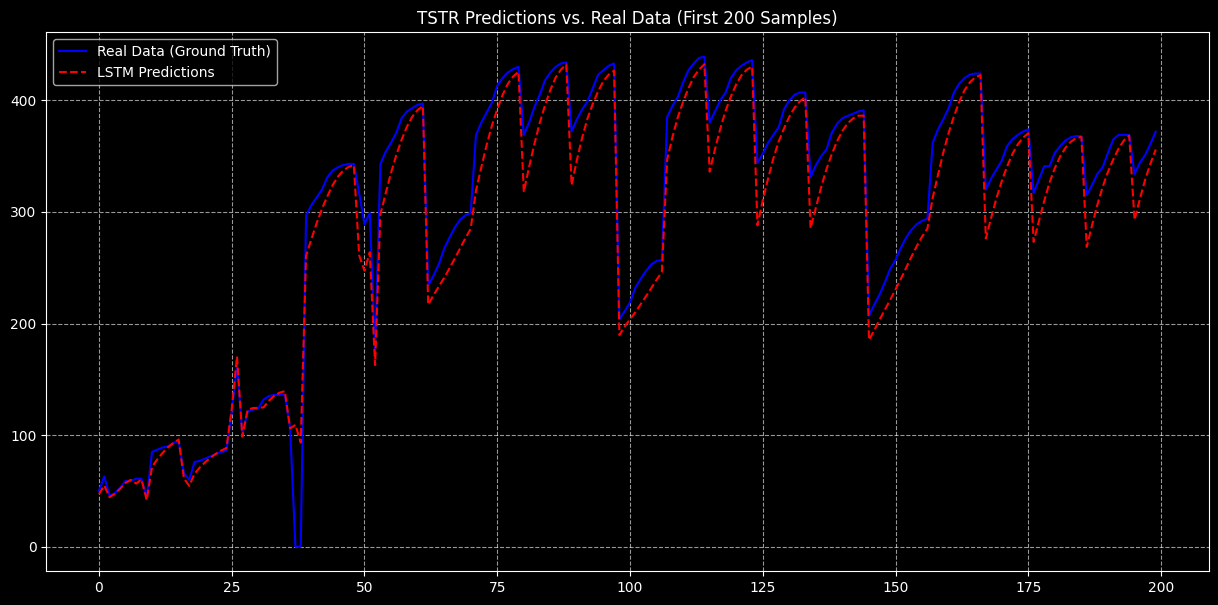


--- ✅ Validation Complete ---


In [4]:
# ===================================================================
# --- CONFIGURATION & EXECUTION ---
# ===================================================================
# 1. DEFINE YOUR FILE PATHS AND PARAMETERS HERE
REAL_DATA_PATH = "../../data/data.csv"
SYNTHETIC_DATA_PATH = (
    "../../data/syntheticData/synthetic_data_vae.csv"
)
TARGET_COLUMN = "cumulative_mite_count"
GROUP_COLUMN = "treatment_id"
SEQUENCE_LENGTH = 15  # The input window size for the LSTM
# 2. RUN THE VALIDATION
run_full_validation(
    real_path=REAL_DATA_PATH,
    synthetic_path=SYNTHETIC_DATA_PATH,
    target_col=TARGET_COLUMN,
    group_col=GROUP_COLUMN,
    seq_length=SEQUENCE_LENGTH,
)

--- 🚀 Starting Full Validation Suite ---
✅ Data loaded successfully.

--- 📊 Section 1: Descriptive Statistics ---
         Real Data  Synthetic Data
count  3786.000000     3786.000000
mean    156.924194       70.547451
std     147.071416       20.312529
min       0.000000       11.329890
25%      28.000000       58.609560
50%     118.000000       72.240490
75%     257.000000       82.305010
max     751.000000      130.790450


--- 🎨 Section 2: Visual Comparison of Random Groups ---
   Plotting random sample groups: ['T8R3', 'T7R2', 'T1R21']


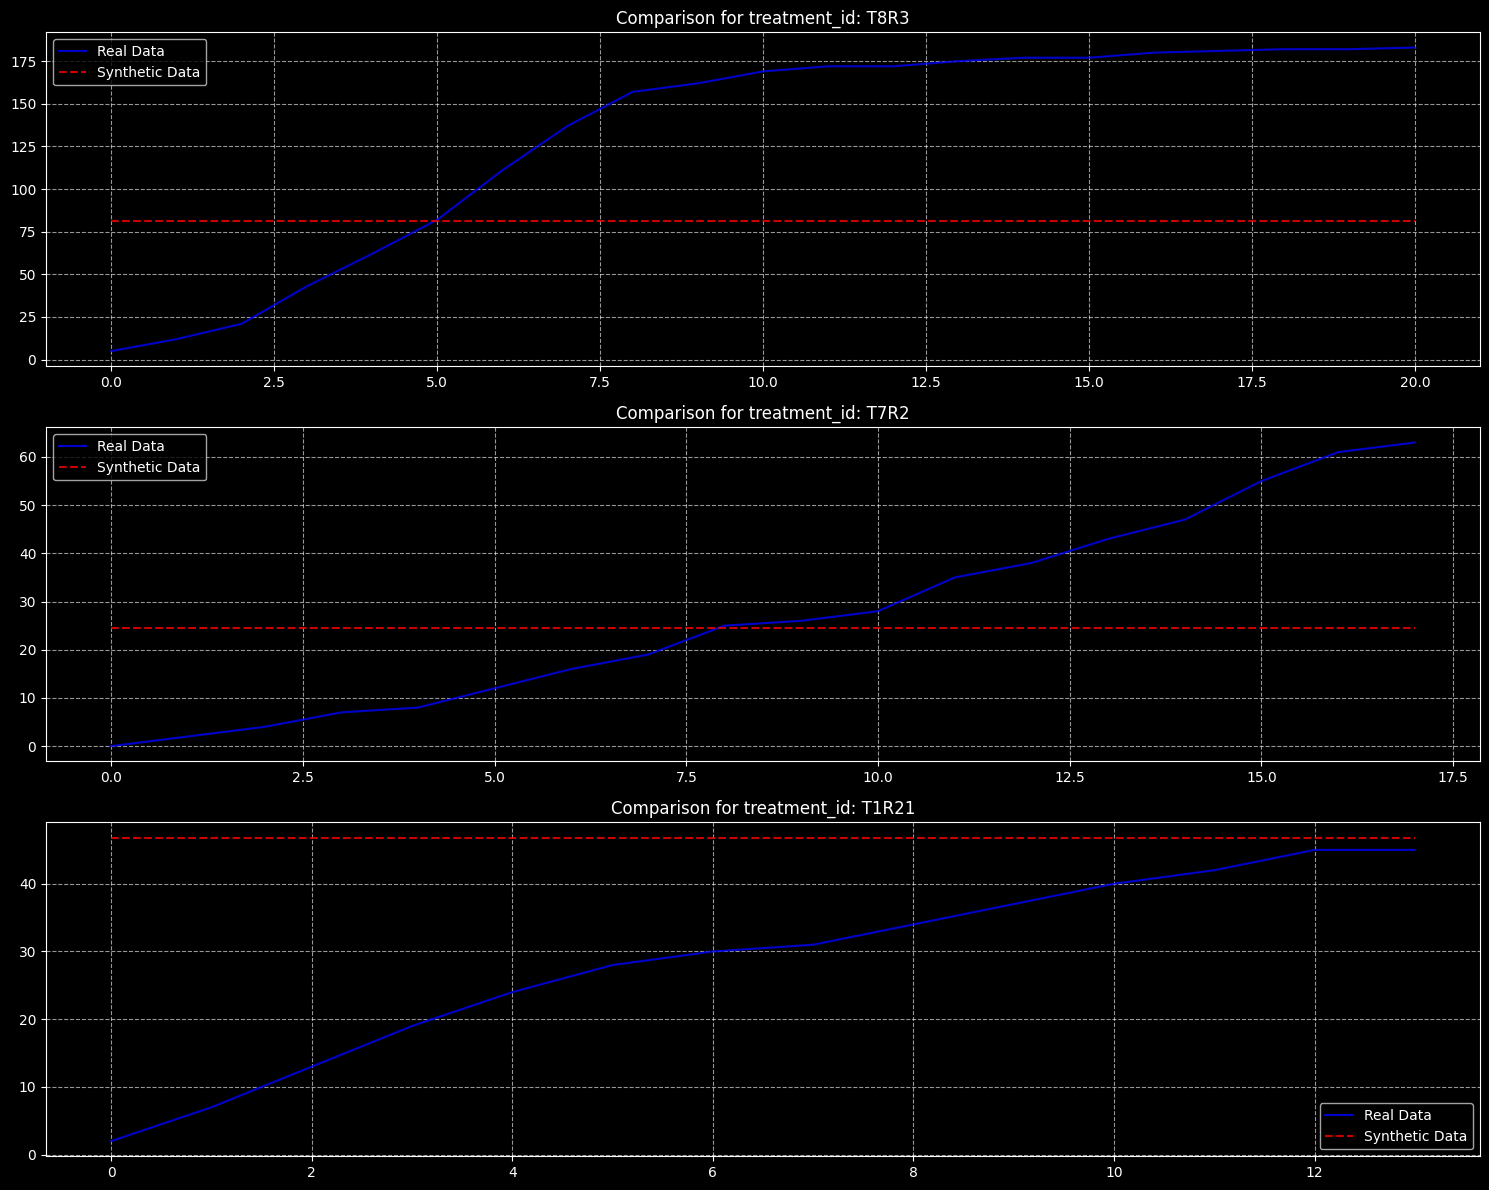


--- 📈 Section 3: Distribution Comparison (KDE Plot) ---


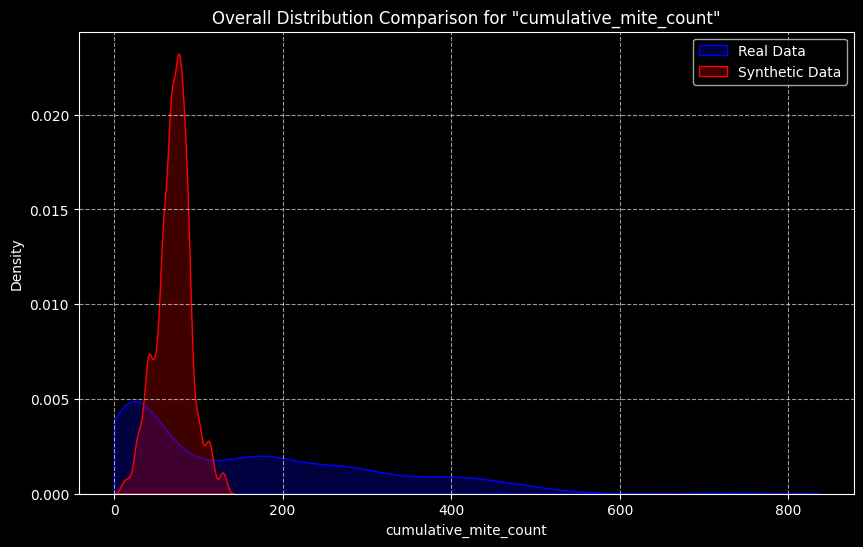


--- ⏳ Section 4: Autocorrelation (ACF & PACF) ---


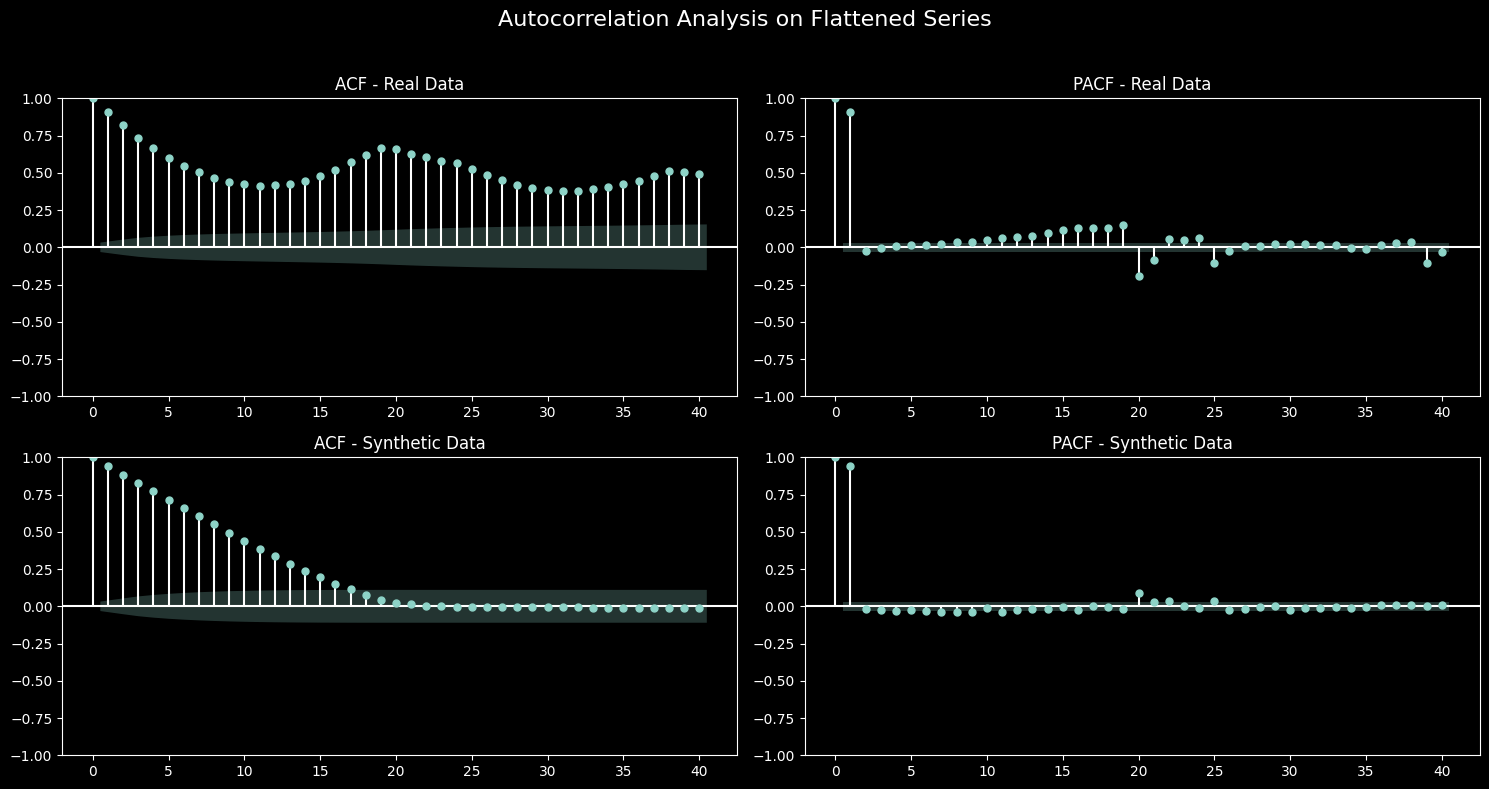


--- 🤖 Section 5: Train-Synthetic-Test-Real (TSTR) Evaluation ---
   Creating sequences within each group...
   Generated 790 training sequences from synthetic data.
   Generated 790 testing sequences from real data.
   Building and training LSTM model on synthetic data...


e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Evaluating model on real data sequences...

   --- TSTR Performance Metrics ---
   (Note: MAPE calculated on 788 of 790 non-zero data points)
   RMSE: 84.5409
   MAE:  69.8812
   MSE:  7147.1673
   MAPE: 24.23%
   R²:   0.6182

--- 📈 Section 6: TSTR Prediction Visualization (Sample) ---


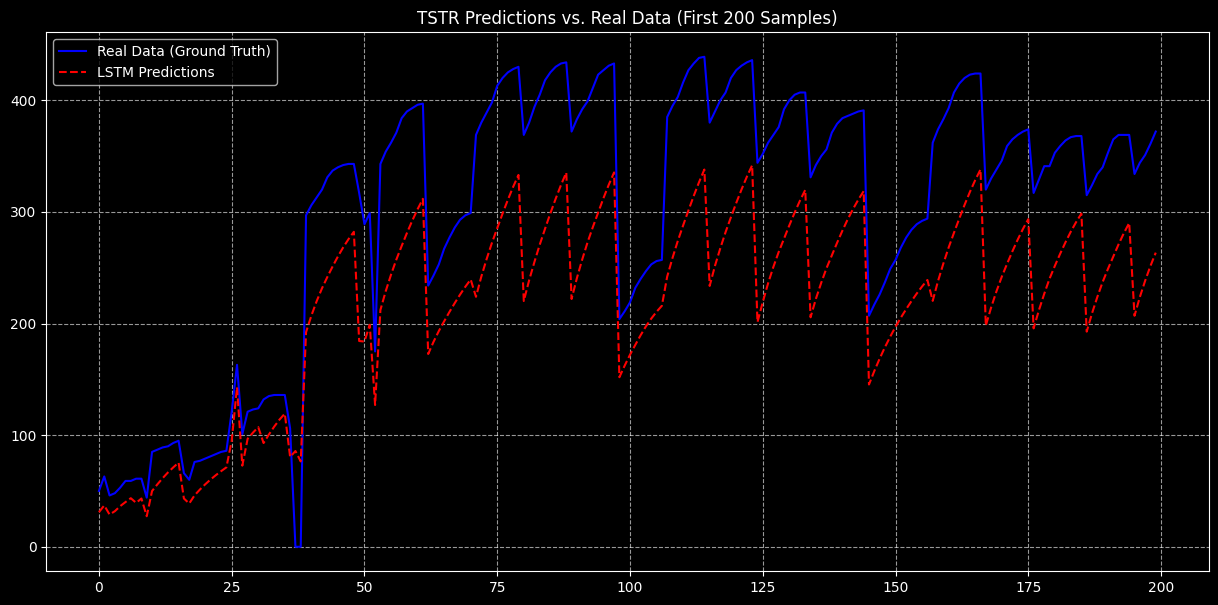


--- ✅ Validation Complete ---


In [5]:
# ===================================================================
# --- CONFIGURATION & EXECUTION ---
# ===================================================================
# 1. DEFINE YOUR FILE PATHS AND PARAMETERS HERE
REAL_DATA_PATH = "../../data/data.csv"
SYNTHETIC_DATA_PATH = (
    "../../data/syntheticData/synthetic_data_gan2.csv"
)
TARGET_COLUMN = "cumulative_mite_count"
GROUP_COLUMN = "treatment_id"
SEQUENCE_LENGTH = 15  # The input window size for the LSTM
# 2. RUN THE VALIDATION
run_full_validation(
    real_path=REAL_DATA_PATH,
    synthetic_path=SYNTHETIC_DATA_PATH,
    target_col=TARGET_COLUMN,
    group_col=GROUP_COLUMN,
    seq_length=SEQUENCE_LENGTH,
)

--- 🚀 Starting Full Validation Suite ---
✅ Data loaded successfully.

--- 📊 Section 1: Descriptive Statistics ---
         Real Data  Synthetic Data
count  3786.000000     3786.000000
mean    156.924194      167.085955
std     147.071416      128.686394
min       0.000000        0.000000
25%      28.000000       65.179375
50%     118.000000      132.906990
75%     257.000000      246.933753
max     751.000000      652.095700


--- 🎨 Section 2: Visual Comparison of Random Groups ---
   Plotting random sample groups: ['T7R16', 'T2R28', 'T1R26']


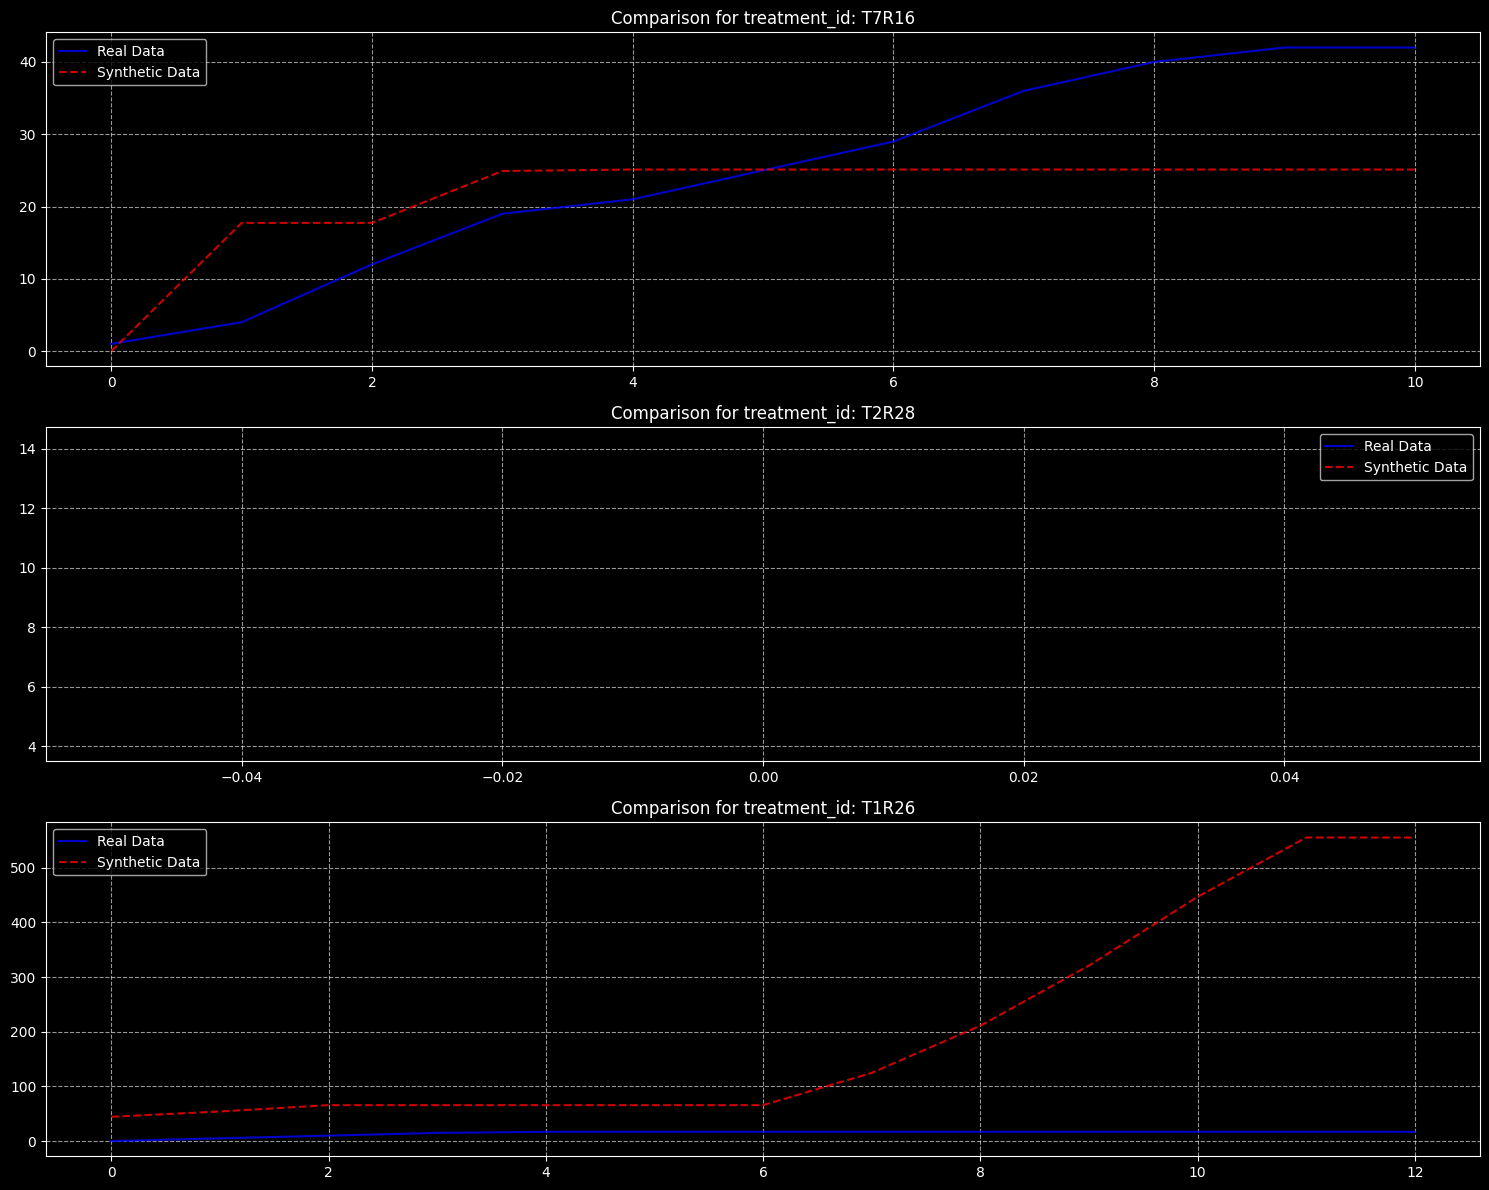


--- 📈 Section 3: Distribution Comparison (KDE Plot) ---


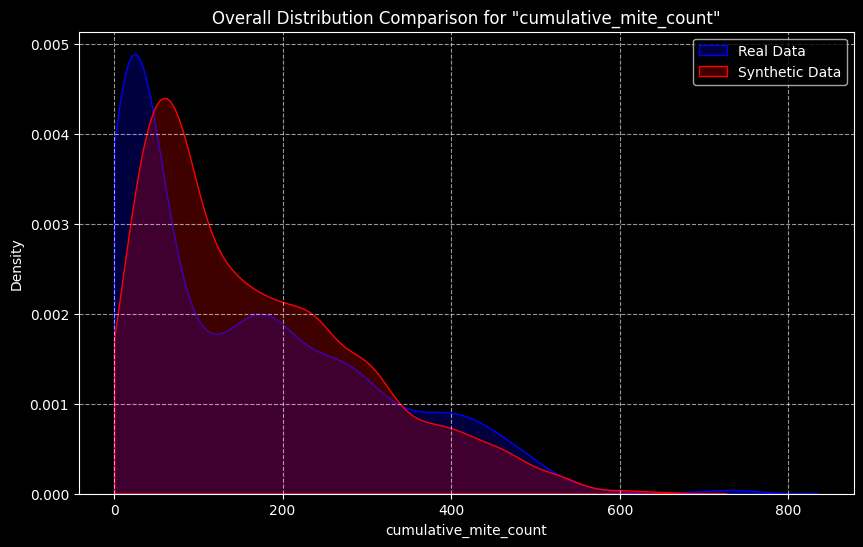


--- ⏳ Section 4: Autocorrelation (ACF & PACF) ---


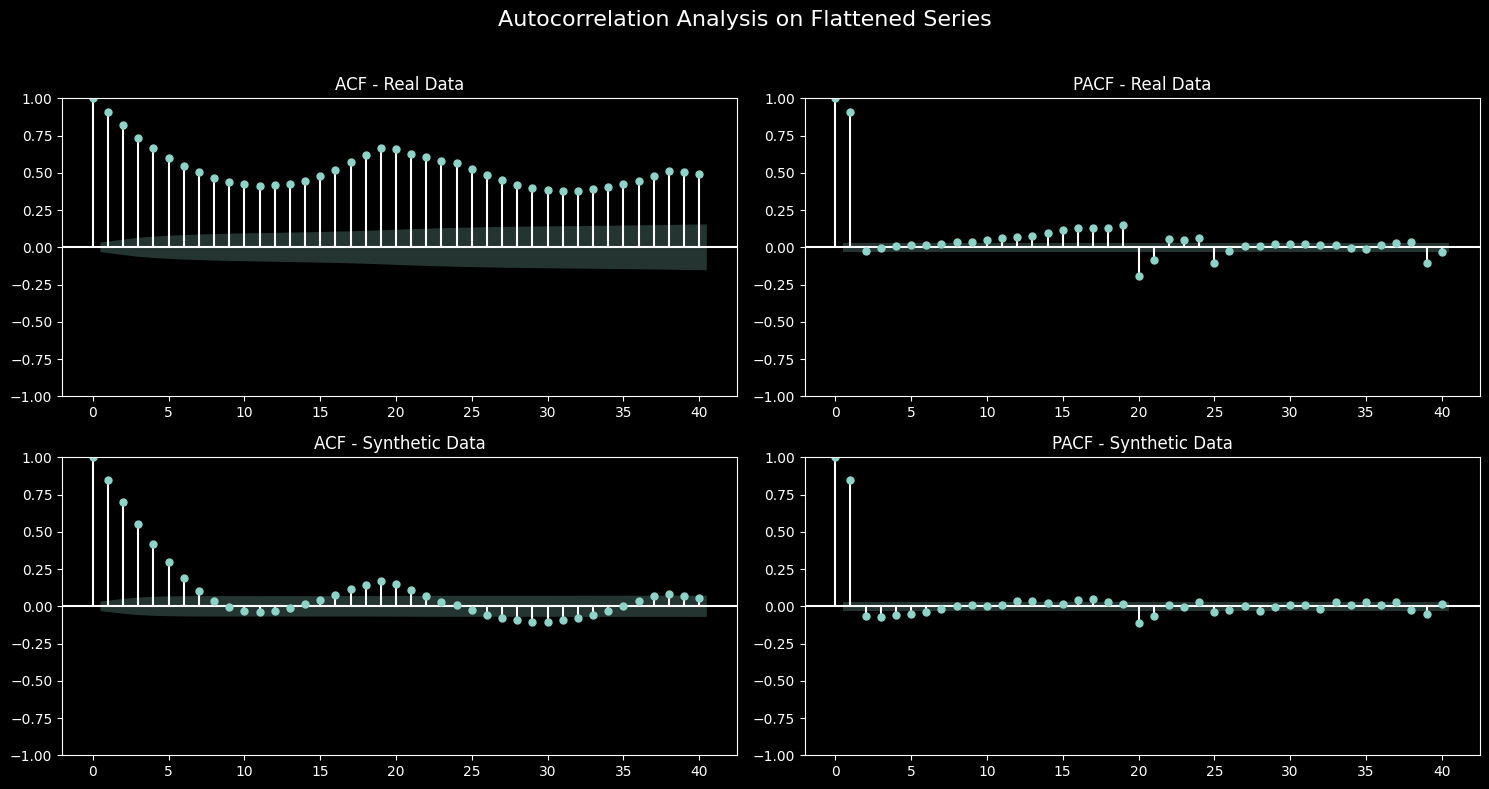


--- 🤖 Section 5: Train-Synthetic-Test-Real (TSTR) Evaluation ---
   Creating sequences within each group...
   Generated 790 training sequences from synthetic data.
   Generated 790 testing sequences from real data.
   Building and training LSTM model on synthetic data...


e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Evaluating model on real data sequences...

   --- TSTR Performance Metrics ---
   (Note: MAPE calculated on 788 of 790 non-zero data points)
   RMSE: 11.9009
   MAE:  7.7020
   MSE:  141.6320
   MAPE: 3.49%
   R²:   0.9924

--- 📈 Section 6: TSTR Prediction Visualization (Sample) ---


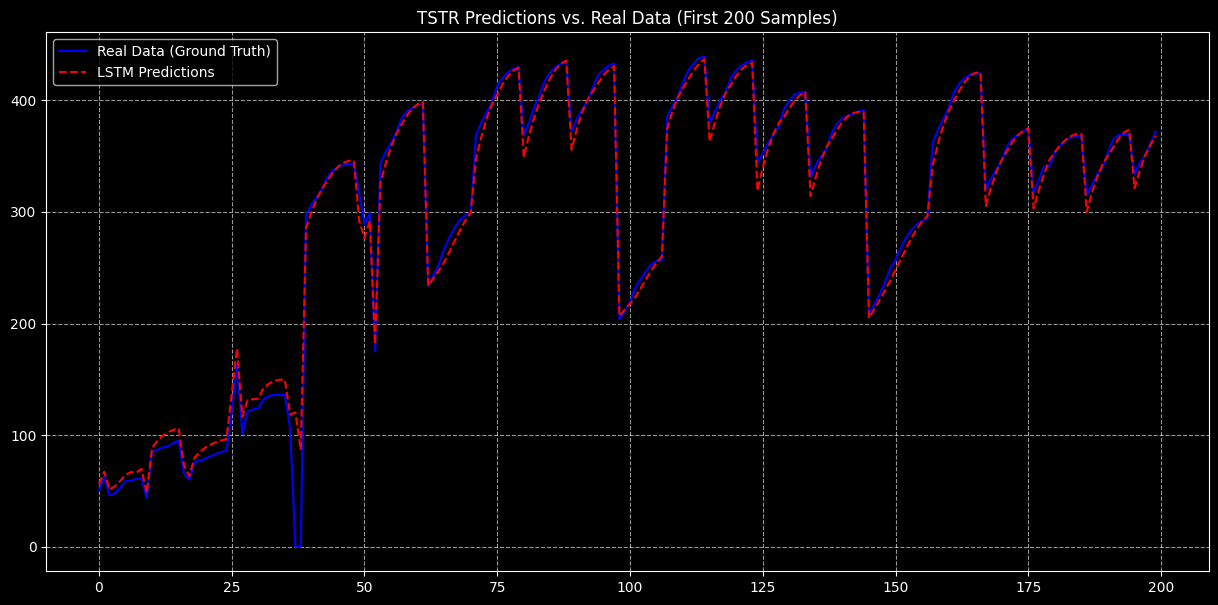


--- ✅ Validation Complete ---


In [6]:
# ===================================================================
# --- CONFIGURATION & EXECUTION ---
# ===================================================================
# 1. DEFINE YOUR FILE PATHS AND PARAMETERS HERE
REAL_DATA_PATH = "../../data/data.csv"
SYNTHETIC_DATA_PATH = (
    "../../data/syntheticData/synthetic_data_diffusion.csv"
)
TARGET_COLUMN = "cumulative_mite_count"
GROUP_COLUMN = "treatment_id"
SEQUENCE_LENGTH = 15  # The input window size for the LSTM
# 2. RUN THE VALIDATION
run_full_validation(
    real_path=REAL_DATA_PATH,
    synthetic_path=SYNTHETIC_DATA_PATH,
    target_col=TARGET_COLUMN,
    group_col=GROUP_COLUMN,
    seq_length=SEQUENCE_LENGTH,
)

--- 🚀 Starting Full Validation Suite ---
✅ Data loaded successfully.

--- 📊 Section 1: Descriptive Statistics ---
         Real Data  Synthetic Data
count  3786.000000    18930.000000
mean    156.924194     1188.810685
std     147.071416     2604.319498
min       0.000000        0.000000
25%      28.000000       14.000000
50%     118.000000      105.000000
75%     257.000000      905.508599
max     751.000000    28602.074547


--- 🎨 Section 2: Visual Comparison of Random Groups ---
   No common group IDs found between real and synthetic data. Skipping plot.

--- 📈 Section 3: Distribution Comparison (KDE Plot) ---


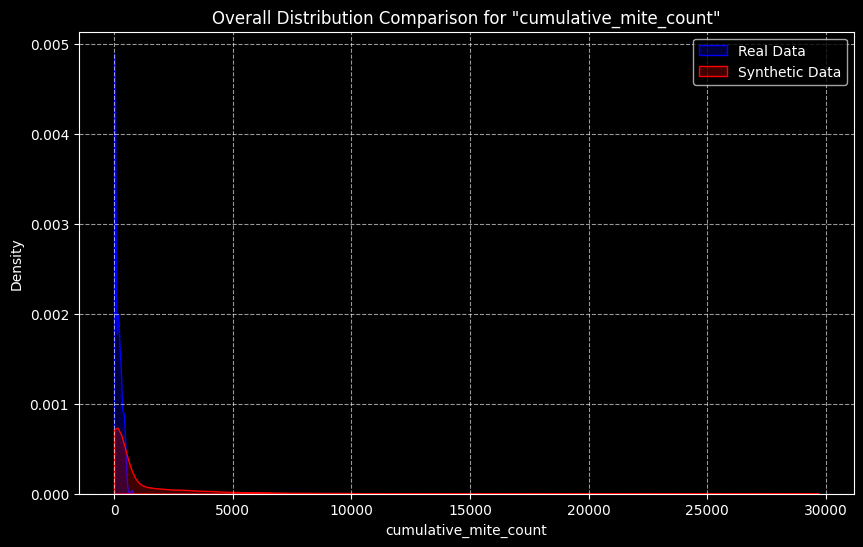


--- ⏳ Section 4: Autocorrelation (ACF & PACF) ---


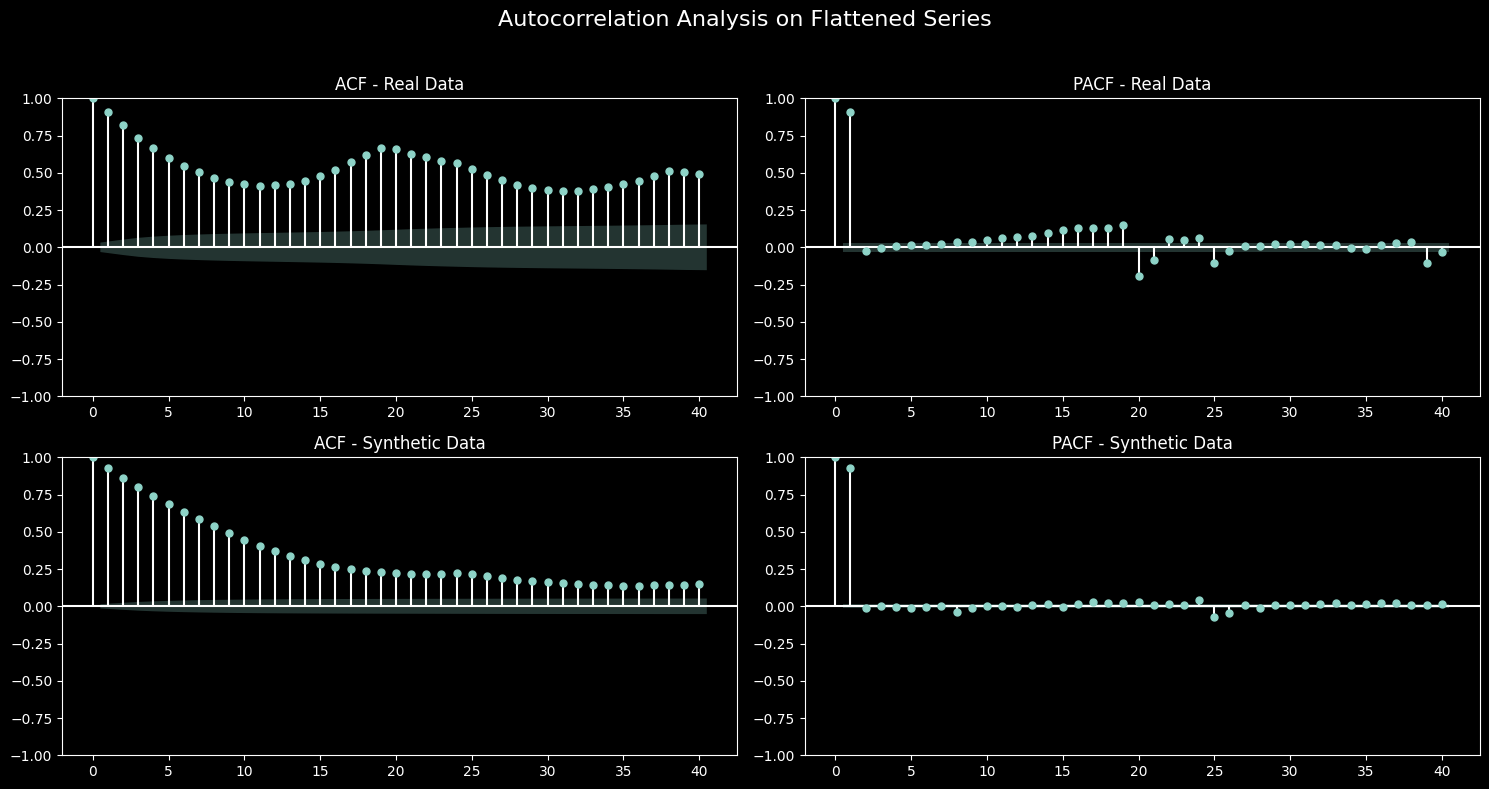


--- 🤖 Section 5: Train-Synthetic-Test-Real (TSTR) Evaluation ---
   Creating sequences within each group...
   Generated 3950 training sequences from synthetic data.
   Generated 790 testing sequences from real data.
   Building and training LSTM model on synthetic data...


e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Evaluating model on real data sequences...

   --- TSTR Performance Metrics ---
   (Note: MAPE calculated on 788 of 790 non-zero data points)
   RMSE: 18.8190
   MAE:  13.1302
   MSE:  354.1536
   MAPE: 6.18%
   R²:   0.9811

--- 📈 Section 6: TSTR Prediction Visualization (Sample) ---


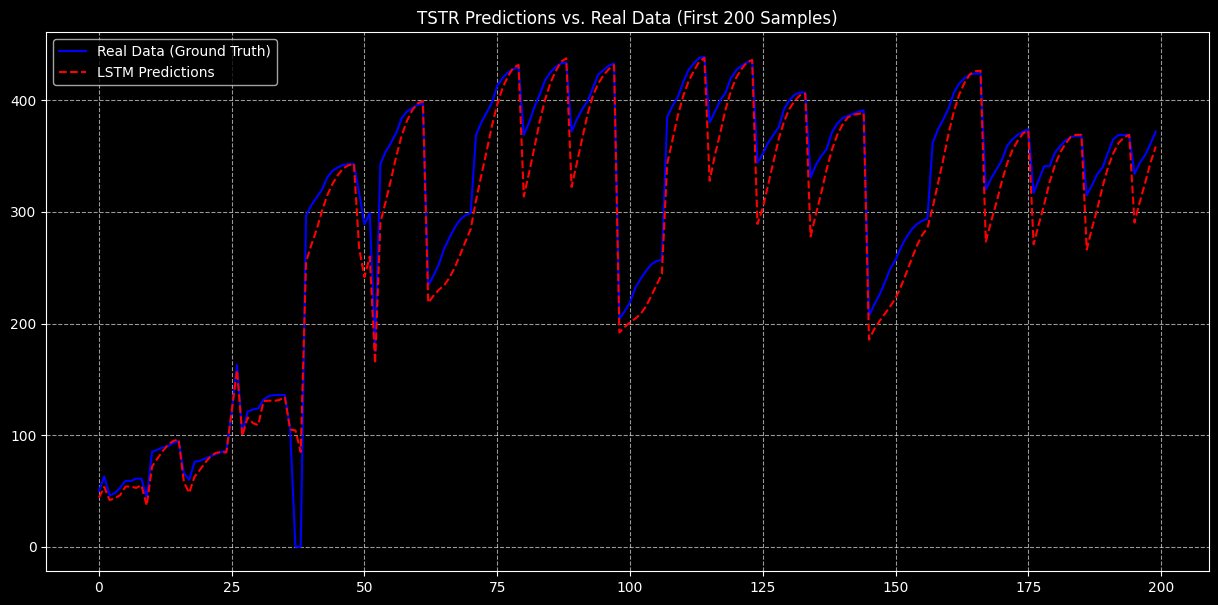


--- ✅ Validation Complete ---


In [3]:
# ===================================================================
# --- CONFIGURATION & EXECUTION ---
# ===================================================================
# 1. DEFINE YOUR FILE PATHS AND PARAMETERS HERE
REAL_DATA_PATH = "../../data/data.csv"
SYNTHETIC_DATA_PATH = (
    "../../data/syntheticData/synthetic_data_sarima_statsmodels_5x.csv"
)
TARGET_COLUMN = "cumulative_mite_count"
GROUP_COLUMN = "treatment_id"
SEQUENCE_LENGTH = 15  # The input window size for the LSTM
# 2. RUN THE VALIDATION
run_full_validation(
    real_path=REAL_DATA_PATH,
    synthetic_path=SYNTHETIC_DATA_PATH,
    target_col=TARGET_COLUMN,
    group_col=GROUP_COLUMN,
    seq_length=SEQUENCE_LENGTH,
)